# PyPSA Bootcamp - Bohol island

**KOUAME Koffi Fidele** - IMP-EGH Master, Track 6 System Analysis

Un cours progressif en 8 chapitres, chacun bati sur le dataset reel de Bohol. Code commente, resultats imprimes, analyse et figures a chaque etape.

---



<hr style='border:2px solid #1E81D4'>


# Chapter 1 - Installation, setup and the Bohol dataset

Welcome to the **PyPSA bootcamp**. The whole course is built around one real
system: the electricity island of **Bohol** (Philippines). Every chapter adds
one new modelling idea on top of the same data, exactly the way you would learn
a programming language one concept at a time.

PyPSA (*Python for Power System Analysis*) is a free library that lets you:

- build a power network (buses, lines, generators, loads, storage) as a set of tables,
- run a **power flow** (how the current actually distributes in the grid),
- run an **optimisation** (how to operate or invest in the system at least cost).

**Goals of this chapter**
- Check that PyPSA and a linear solver (HiGHS) are installed and working.
- Load the Bohol dataset and look at what is inside it.
- Understand the eight component types we will use for the rest of the bootcamp.

### 1.1 Check the installation

If the imports below run without error, you are ready. `pypsa.__version__`
should be 1.x. We also silence a few harmless warnings so the output stays clean.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
for _n in ("pypsa", "linopy", "pypsa.consistency"):
    logging.getLogger(_n).setLevel(logging.ERROR)

from pathlib import Path
import numpy as np
import pandas as pd
import pypsa

print("PyPSA   :", pypsa.__version__)
print("pandas  :", pd.__version__)
print("numpy   :", np.__version__)

PyPSA   : 1.4.0
pandas  : 3.1.1
numpy   : 2.4.6


### 1.2 Check the solver

Optimisation chapters (4 to 8) need a Linear Programming solver. PyPSA ships
with **HiGHS**, which is open source and needs no license. We test it on a
trivial one-line problem: one 100 MW generator feeding one 80 MW load. The
only possible answer is "produce 80 MW", at a cost of 80 x 10 = 800.

In [2]:
test = pypsa.Network()
test.add("Bus", "b")
test.add("Generator", "g", bus="b", p_nom=100, marginal_cost=10)
test.add("Load", "d", bus="b", p_set=80)

status, condition = test.optimize(solver_name="highs",
                                  solver_options={"output_flag": False},
                                  log_to_console=False)
print("solver status :", status, "/", condition)
print("generator output :", round(test.generators_t.p.iloc[0, 0], 1), "MW")
print("total cost       :", round(float(test.objective), 1), "currency units")
assert status == "ok", "HiGHS is not available - check the installation"
print("\nSolver works. You are ready for the whole bootcamp.")

solver status : ok / optimal
generator output : 80.0 MW
total cost       : 800.0 currency units

Solver works. You are ready for the whole bootcamp.


### 1.3 Locate the Bohol dataset

The dataset is a single Excel file with seven sheets. We find it whether the
notebook is run from the project root or from the `notebooks/` folder.

In [3]:
DATA = next(p for p in [Path("data"), Path("../data"), Path("pypsa-bootcamp/data")]
            if (p / "PyPSA_Dataset_Bohol.xlsx").exists())
XLS = DATA / "PyPSA_Dataset_Bohol.xlsx"
sheets = pd.ExcelFile(XLS).sheet_names
print("dataset folder :", DATA.resolve())
print("sheets         :", sheets)

dataset folder : /home/user/piggy-cast/pypsa-bootcamp/data
sheets         : ['buses', 'loads', 'carriers', 'generators', 'lines', 'loads_t', 'generators_t']


### 1.4 What is in each sheet

The seven sheets map one-to-one onto PyPSA components. This is the vocabulary
of the whole bootcamp, so take a minute here.

| Sheet | PyPSA component | Meaning |
| --- | --- | --- |
| `buses` | **Bus** | an electrical node (a substation), at a voltage level |
| `lines` | **Line** | an AC transmission line joining two buses |
| `loads` | **Load** | electricity demand connected to a bus |
| `generators` | **Generator** | a power plant (diesel, hydro, grid import) |
| `carriers` | **Carrier** | a technology/fuel, with its cost and CO2 content |
| `loads_t` | time series | hourly demand for one day (the `_t` means "time dependent") |
| `generators_t` | time series | hourly availability of solar and wind |

Let us look at the static sheets.

In [4]:
buses = pd.read_excel(XLS, "buses")
print("BUSES - the three nodes of the Bohol grid")
print(buses.to_string(index=False))

BUSES - the three nodes of the Bohol grid
     name          x         y  v_nom
07CORELLA 123.959325  9.699520  138.0
  07TAPAL 124.519576 10.060901   13.8
   07UBAY 124.511428 10.026670  138.0


Three buses: **07CORELLA** and **07UBAY** at 138 kV (the transmission backbone)
and **07TAPAL** at 13.8 kV (a distribution pocket). The `x` and `y` columns are
the real longitude/latitude, which we will use to draw the network on a map.

In [5]:
lines = pd.read_excel(XLS, "lines")
print("LINES - the AC corridors")
print(lines.to_string(index=False))
print("\nGENERATORS - the power plants")
print(pd.read_excel(XLS, "generators").to_string(index=False))

LINES - the AC corridors
                name  cables   bus0      bus1  s_nom         x        r
   69_07UBAY_07TAPAL       1 07UBAY   07TAPAL     69  1.875327 0.305012
138_07UBAY_07CORELLA       1 07UBAY 07CORELLA    138 12.089197 8.512958
 69_07UBAY_07CORELLA       1 07UBAY 07CORELLA     69 33.857589 5.506756

GENERATORS - the power plants


            name       bus  p_nom carrier  build_year
    07TPLPB4_U01   07TAPAL    7.0  Diesel        2005
    07TPLPB4_U02   07TAPAL    7.0  Diesel        2005
    07TPLPB4_U03   07TAPAL    7.0  Diesel        2005
    07TPLPB4_U04   07TAPAL    8.0  Diesel        2005
      07BDPP_U01 07CORELLA    4.0  Diesel        1978
      07BDPP_U02 07CORELLA    4.0  Diesel        1978
      07BDPP_U03 07CORELLA    4.2  Diesel        1978
      07BDPP_U04 07CORELLA    4.0  Diesel        1978
    07JANOPO_G01 07CORELLA    5.0   Hydro        1992
     07LOBOC_G01 07CORELLA    1.2   Hydro        2019
     07LOBOC_G02 07CORELLA    1.2   Hydro        2019
    07SEVILL_G01 07CORELLA    2.5   Hydro        2008
Grid_electricity    07UBAY  138.0    Grid        2005


Thirteen generators: four diesel units at Tapal, four older diesel units and
four small hydro units at Corella, plus one "Grid" generator at Ubay that stands
for the submarine cable importing power from the neighbouring island of Leyte.

### 1.5 Carriers: where the economics live

A **Carrier** is a fuel or technology. PyPSA uses it to attach two things to
every plant of that type: its **CO2 content** and the raw numbers we turn into
a **marginal cost** (currency per MWh produced) and a **capital cost** (currency
per MW of capacity). We will compute those in Chapter 4; for now just read them.

In [6]:
carriers = pd.read_excel(XLS, "carriers")
print("CARRIERS")
print(carriers.to_string(index=False))

CARRIERS
   name   color  co2_emissions    VOM    FOM     fuel   investment  efficiency  lifetime
 Diesel #B41E25         0.2571 6.3493 2.5656 52.91110 3.629700e+05        0.35        25
  Hydro #1E81D4         0.0000 0.0000 1.0000  0.00000 2.274818e+06        0.90        80
  Solar #FDB324         0.0000 0.0106 1.5780  0.00000 8.098118e+05        1.00        35
   Wind #3BBFE5         0.0000 1.5873 1.2514  0.00000 1.183912e+06        1.00        27
Battery #814ad4         0.0000 0.0000 0.2000  0.00000 2.455074e+05        0.95        20
   Grid #b01787         0.1100 0.0000 0.0000 42.73002 1.396283e+04        1.00        40


Reading the economics the way the rest of the bootcamp will:

- **marginal cost** = `VOM + fuel / efficiency` (variable O&M plus the fuel
  burned per MWh of electricity). Diesel burns expensive fuel at 35 % efficiency,
  so it will be costly; hydro and the grid import are cheap.
- **capital cost** = `(1 + FOM) * investment / (lifetime * 365.25)`, i.e. the
  build cost spread over the plant's life and expressed **per day** (our
  optimisation horizon is one day).

In [7]:
econ = carriers.assign(
    marginal_cost=lambda d: (d.VOM + d.fuel / d.efficiency).round(2),
    capital_cost_per_day=lambda d: ((1 + d.FOM) * d.investment / (d.lifetime * 365.25)).round(1),
)[["name", "co2_emissions", "marginal_cost", "capital_cost_per_day"]]
print(econ.to_string(index=False))

   name  co2_emissions  marginal_cost  capital_cost_per_day
 Diesel         0.2571         157.52                 141.7
  Hydro         0.0000           0.00                 155.7
  Solar         0.0000           0.01                 163.3
   Wind         0.0000           1.59                 270.3
Battery         0.0000           0.00                  40.3
   Grid         0.1100          42.73                   1.0


Already a result worth noting: **diesel costs about 157 /MWh, the grid import
about 43 /MWh, and hydro is almost free.** Any least-cost model will lean on
hydro and the cable first and keep diesel for the peak. We will prove it in
Chapter 4.

### 1.6 The time series

The `_t` sheets hold one winter day (2 January 2023) at hourly resolution.

In [8]:
loads_t = pd.read_excel(XLS, "loads_t", index_col=0)
gens_t = pd.read_excel(XLS, "generators_t", index_col=0)
print("Demand (MW) - first hours:")
print(loads_t.head(3).round(2).to_string())
print("\nRenewable availability (fraction of capacity) - midday hours:")
print(gens_t.iloc[9:13].round(3).to_string())
print("\nDaily peak demand:", round(loads_t.sum(axis=1).max(), 1), "MW",
      "| daily energy:", round(loads_t.sum(axis=1).sum(), 0), "MWh")

Demand (MW) - first hours:
                     07CORELLA_LOAD  07UBAY_LOAD
2023-01-02 00:00:00           38.34        19.89
2023-01-02 01:00:00           35.27        18.58
2023-01-02 02:00:00           33.06        17.44

Renewable availability (fraction of capacity) - midday hours:
                     SOLAR_BOHOL  WIND_BOHOL
2023-01-02 09:00:00        0.589       0.842
2023-01-02 10:00:00        0.656       0.854
2023-01-02 11:00:00        0.666       0.855
2023-01-02 12:00:00        0.620       0.844

Daily peak demand: 82.6 MW | daily energy: 1516.0 MWh


Solar peaks at noon (~0.67 of its capacity) and is zero at night; wind is
strong all day on this date (0.4 to 0.85). The island peaks near 84 MW.

## Summary of Chapter 1

- PyPSA and the HiGHS solver are installed and solve a trivial problem correctly.
- The Bohol dataset has **3 buses, 3 lines, 13 generators, 6 carriers** and a
  24-hour demand and renewable profile.
- Economics come from the carriers: **diesel ~157, grid ~43, hydro ~0** per MWh.
- Next chapter we build our very first network by hand and read its tables.



<hr style='border:2px solid #1E81D4'>


# Chapter 2 - Your first PyPSA network

Everything in PyPSA lives inside one `Network` object. The components (buses,
loads, generators, lines) are stored as **pandas tables** that you fill with
`n.add(...)`. In this chapter we build the smallest useful model by hand - a
single bus with the demand of Corella and two plants - so you can see exactly
what those tables look like before we scale up to the real island.

**Goals of this chapter**
- Use `n.add()` to create carriers, a bus, a load and generators.
- Read the component tables `n.buses`, `n.loads`, `n.generators`.
- Run `n.statistics()` for a first automatic summary.
- Understand the "copper plate" assumption (one bus = no grid limits).

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
for _n in ("pypsa", "linopy", "pypsa.consistency"):
    logging.getLogger(_n).setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import pypsa

print("PyPSA version:", pypsa.__version__)

PyPSA version: 1.4.0


### 2.1 Create the network and add components

The pattern is always `n.add("ComponentType", "name", **parameters)`. Good
habit: declare the **Carrier** first, so every plant can point at a known fuel
and PyPSA never warns about an undefined carrier.

In [2]:
n = pypsa.Network()

# 1) carriers (fuels / technologies) - cost and CO2 attached later
n.add("Carrier", "Diesel", co2_emissions=0.2571)   # tonnes CO2 per MWh thermal
n.add("Carrier", "Grid", co2_emissions=0.1100)      # imported electricity

# 2) one bus: the 138 kV node at Corella. With a single bus, every plant and the
#    load sit at the same place: this is the "copper plate" - no line can limit
#    anything. We relax that in Chapter 3.
n.add("Bus", "Corella", v_nom=138)

# 3) the demand at Corella (its daytime value, held constant for now)
n.add("Load", "Corella_load", bus="Corella", p_set=42.0)   # MW

# 4) two ways to serve it: cheap imported grid power, expensive local diesel
n.add("Generator", "Grid_import", bus="Corella", carrier="Grid",
      p_nom=138, marginal_cost=43.0)      # large cable, cheap
n.add("Generator", "Diesel_local", bus="Corella", carrier="Diesel",
      p_nom=30, marginal_cost=157.0)      # small, expensive

print("buses:", len(n.buses), "| loads:", len(n.loads),
      "| generators:", len(n.generators), "| carriers:", len(n.carriers))

buses: 1 | loads: 1 | generators: 2 | carriers: 2


### 2.2 Look at the component tables

Each component type is a DataFrame indexed by the name you gave. PyPSA fills in
every attribute you did not set with its default value, so the tables are wider
than what we typed.

In [3]:
print("n.buses")
print(n.buses[["v_nom"]].to_string())
print("\nn.loads")
print(n.loads[["bus", "p_set"]].to_string())
print("\nn.generators")
print(n.generators[["bus", "carrier", "p_nom", "marginal_cost"]].to_string())

n.buses
         v_nom
name          
Corella  138.0

n.loads
                  bus  p_set
name                        
Corella_load  Corella   42.0

n.generators
                  bus carrier  p_nom  marginal_cost
name                                               
Grid_import   Corella    Grid  138.0           43.0
Diesel_local  Corella  Diesel   30.0          157.0


### 2.3 A first dispatch by hand, then by PyPSA

With 42 MW of demand and a 138 MW cheap cable, the obvious least-cost answer is:
**import all 42 MW, run no diesel.** Let us ask the optimiser and check it agrees.

In [4]:
status, cond = n.optimize(solver_name="highs",
                          solver_options={"output_flag": False},
                          log_to_console=False)
print("status:", status)
print("\nDispatch (MW):")
print(n.generators_t.p.iloc[0].round(2).to_string())
print("\nTotal cost:", round(float(n.objective), 1),
      "= 42 MW x 43 =", 42 * 43)

status: ok

Dispatch (MW):
name
Grid_import     42.0
Diesel_local    -0.0

Total cost: 1806.0 = 42 MW x 43 = 1806


As expected the diesel stays off. The grid carries the whole load because it is
cheaper and big enough. This is the **merit order** in miniature; Chapter 4
makes it the central idea.

### 2.4 `n.statistics()` - the automatic summary

Once a network is solved, `n.statistics()` aggregates the result per carrier:
installed capacity, energy supplied, cost, CO2. It is the fastest way to read a
result and we will use it in every later chapter.

In [5]:
stats = n.statistics()
cols = [c for c in ["Optimal Capacity", "Supply", "Operational Expenditure"] if c in stats.columns]
print(stats[cols].round(1).to_string())

                  Optimal Capacity  Supply  Operational Expenditure
Generator Diesel              30.0     0.0                      0.0
          Grid               138.0    42.0                   1806.0
Load      -                    0.0     0.0                      0.0


### 2.5 What one bus cannot tell you

A single bus assumes the grid is a perfect copper plate: infinite line capacity,
no voltage drop, no losses. That is fine for a first economic look, but a real
island has a 138 kV backbone and a weak 13.8 kV pocket, and the lines **do**
limit the flows and drop the voltage. To see that, we need more than one bus and
a real power flow - which is exactly Chapter 3.

To make the point concrete, add the second real bus (Ubay) and the cable between
them, then look at the (still trivial) line flow.

In [6]:
n.add("Bus", "Ubay", v_nom=138)
# move the cheap grid import to Ubay, where the submarine cable actually lands
n.generators.loc["Grid_import", "bus"] = "Ubay"
# a line from Ubay to Corella (per-unit impedance converted to ohm in Chapter 3)
n.add("Line", "Ubay-Corella", bus0="Ubay", bus1="Corella", x=12.09, r=8.51, s_nom=138)

n.optimize(solver_name="highs", solver_options={"output_flag": False}, log_to_console=False)
print("Power now flows Ubay -> Corella over the cable:")
print(n.lines_t.p0.iloc[0].round(2).to_string(), "MW")

Power now flows Ubay -> Corella over the cable:
name
Ubay-Corella    42.0 MW


## Summary of Chapter 2

- A PyPSA model is a `Network` of component **tables** filled with `n.add()`.
- With a single bus the grid is a copper plate: the cheapest generator that is
  big enough serves the whole load. Here the 43 /MWh grid import beats the
  157 /MWh diesel and diesel stays off.
- `n.statistics()` gives a one-line summary per carrier.
- A single bus hides the grid. Chapter 3 introduces buses, lines and the two
  kinds of power flow that reveal voltages, flows and losses.



<hr style='border:2px solid #1E81D4'>


# Chapter 3 - Power flow: how the current really distributes

Chapter 2 used a single bus, so the grid could carry anything. Real grids have
lines with resistance and reactance: current splits between parallel paths, the
voltage sags far from the source, and a few percent of the energy is lost as
heat. **Power flow** is the calculation that reveals all of this.

We now build the **real 3-bus Bohol network** from the dataset and solve it two
ways:

- `n.pf()` - the full **AC** (non-linear) power flow: voltages, angles, reactive
  power, losses. The physical truth.
- `n.lpf()` - the **linear/DC** approximation: fast, no losses, voltages assumed
  flat at 1.0 pu. The workhorse of large planning studies.

**Goals of this chapter**
- Build buses and lines from the dataset, in SI units (ohm, kV, MVA).
- Understand the per-unit system that links ohm to the "pu" voltages PyPSA reports.
- Run and compare `n.pf()` and `n.lpf()`.
- Diagnose an undervoltage and fix it with a shunt capacitor.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
for _n in ("pypsa", "linopy"):
    logging.getLogger(_n).setLevel(logging.ERROR)

from pathlib import Path
import numpy as np
import pandas as pd
import pypsa

DATA = next(p for p in [Path("data"), Path("../data"), Path("pypsa-bootcamp/data")]
            if (p / "PyPSA_Dataset_Bohol.xlsx").exists())
XLS = DATA / "PyPSA_Dataset_Bohol.xlsx"

### 3.1 Build the network from the dataset

We loop over the `buses` and `lines` sheets. Lines in PyPSA are given in **SI
units**: resistance `r` and reactance `x` in **ohm**, nominal apparent power
`s_nom` in **MVA**. Those are exactly the columns in the sheet.

In [2]:
buses = pd.read_excel(XLS, "buses")
lines = pd.read_excel(XLS, "lines")

n = pypsa.Network()
for b in buses.itertuples():
    # v_nom in kV; x,y are real longitude/latitude for the map later
    n.add("Bus", b.name, v_nom=b.v_nom, x=b.x, y=b.y)

for l in lines.itertuples():
    n.add("Line", l.name, bus0=l.bus0, bus1=l.bus1,
          r=l.r, x=l.x, s_nom=l.s_nom)   # ohm, ohm, MVA

print(n.buses[["v_nom"]].to_string())
print()
print(n.lines[["bus0", "bus1", "r", "x", "s_nom"]].to_string())

           v_nom
name            
07CORELLA  138.0
07TAPAL     13.8
07UBAY     138.0

                        bus0       bus1         r          x  s_nom
name                                                               
69_07UBAY_07TAPAL     07UBAY    07TAPAL  0.305012   1.875327   69.0
138_07UBAY_07CORELLA  07UBAY  07CORELLA  8.512958  12.089197  138.0
69_07UBAY_07CORELLA   07UBAY  07CORELLA  5.506756  33.857589   69.0


The island has a **138 kV backbone** (Corella and Ubay, joined by two parallel
lines) and a weak **13.8 kV spur** to Tapal. Ubay is where the submarine cable
from Leyte lands, so it is our natural slack (reference) bus.

### 3.2 The per-unit system (why PyPSA talks in "pu")

Power engineers rarely quote voltage in kV during a study; they use **per-unit**:
the actual value divided by a nominal base. The base impedance of a bus is

> Z_base = V_nom^2 / S_base      (ohm, with V_nom in kV and S_base in MVA)

A line's impedance in per-unit is then `x_pu = x_ohm / Z_base`. PyPSA stores ohm
but converts internally, which is why `n.buses_t.v_mag_pu` comes back around 1.0.
Let us compute the base for the 138 kV corridor so the numbers feel concrete.

In [3]:
S_BASE = 100.0  # MVA, the usual reference
for v in [138.0, 13.8]:
    z = v ** 2 / S_BASE
    print(f"V_nom = {v:6.1f} kV  ->  Z_base = {z:8.2f} ohm  (on a {S_BASE:.0f} MVA base)")

xpu = lines.loc[lines.name == "138_07UBAY_07CORELLA", "x"].iloc[0] / (138 ** 2 / S_BASE)
print(f"\nExample: the 138 kV line reactance 12.09 ohm = {xpu:.4f} pu on 100 MVA")

V_nom =  138.0 kV  ->  Z_base =   190.44 ohm  (on a 100 MVA base)
V_nom =   13.8 kV  ->  Z_base =     1.90 ohm  (on a 100 MVA base)

Example: the 138 kV line reactance 12.09 ohm = 0.0635 pu on 100 MVA


### 3.3 Attach generation and demand, then run the AC power flow

For a power flow we need:
- a **slack** generator (here the Grid/cable at Ubay) that balances the system
  and fixes the reference voltage and angle,
- **loads** with both active power `p_set` (MW) and reactive power `q_set`
  (MVAr). We assume a 0.95 power factor, so `Q = P * tan(acos(0.95))`.

We take the evening peak hour, when demand is highest and the voltage problem
is worst.

In [4]:
loads_t = pd.read_excel(XLS, "loads_t", index_col=0)
peak_hour = loads_t.sum(axis=1).idxmax()
pf_tan = np.tan(np.arccos(0.95))
print("peak hour:", peak_hour)

n.add("Generator", "Grid", bus="07UBAY", control="Slack", p_set=0.0)
for bus, col, name in [("07CORELLA", "07CORELLA_LOAD", "Load_Corella"),
                       ("07UBAY", "07UBAY_LOAD", "Load_Ubay")]:
    p = float(loads_t.loc[peak_hour, col])
    n.add("Load", name, bus=bus, p_set=p, q_set=p * pf_tan)

n.pf()   # Newton-Raphson AC power flow
print("\nDemand served (MW):", round(n.loads.p_set.sum(), 1))
print("\nBus voltages (per unit):")
print(n.buses_t.v_mag_pu.iloc[0].round(4).to_string())

peak hour: 2023-01-02 17:00:00



Demand served (MW): 82.6

Bus voltages (per unit):
name
07CORELLA    0.9764
07TAPAL      1.0000
07UBAY       1.0000


**Read the result.** Ubay is the slack, pinned at 1.000 pu. Corella sits at
about **0.977 pu**: the current drawn by its 53 MW load drops ~2 % of the voltage
across the resistance and reactance of the 138 kV lines. That is the voltage
drop a single bus could never show you.

### 3.4 Line flows and losses

`p0` is the power entering a line at `bus0`, `p1` what leaves at `bus1`. Their
sum is the **loss** (positive = power dissipated as heat in the resistance).

In [5]:
flows = pd.DataFrame({
    "P0 (MW)": n.lines_t.p0.iloc[0],
    "P1 (MW)": n.lines_t.p1.iloc[0],
    "loss (MW)": n.lines_t.p0.iloc[0] + n.lines_t.p1.iloc[0],
    "loading (%)": 100 * np.hypot(n.lines_t.p0, n.lines_t.q0).iloc[0] / n.lines.s_nom,
}).round(3)
print(flows.to_string())
print("\nTotal network losses:", round((n.lines_t.p0.iloc[0] + n.lines_t.p1.iloc[0]).sum(), 3), "MW")

                      P0 (MW)  P1 (MW)  loss (MW)  loading (%)
name                                                          
69_07UBAY_07TAPAL       0.000    0.000      0.000        0.000
138_07UBAY_07CORELLA   41.147  -40.357      0.790       30.457
69_07UBAY_07CORELLA    14.337  -14.242      0.095       26.257

Total network losses: 0.885 MW


The current splits between the two parallel Ubay-Corella lines in inverse
proportion to their impedance: the stronger 138 kV line (lower reactance) takes
the larger share. Nobody dispatched that split - it is pure physics, and only an
AC/DC power flow reveals it.

### 3.5 AC vs DC: what the linear approximation drops

`n.lpf()` solves the **linearised** problem. It assumes every voltage is exactly
1.0 pu and ignores resistance, so it reports **no losses** and a slightly
different flow split. It is far faster and always converges, which is why it is
used for large markets and planning. Compare the two.

In [6]:
ac = n.lines_t.p0.iloc[0].copy()
n.lpf()
dc = n.lines_t.p0.iloc[0]
cmp = pd.DataFrame({"AC p0 (MW)": ac, "DC p0 (MW)": dc, "diff (MW)": ac - dc}).round(3)
print(cmp.to_string())
print("\nDC voltages are all exactly 1.0 pu:",
      bool((n.buses_t.v_mag_pu.iloc[0] == 1.0).all()))
print("=> DC is quick and robust, but blind to voltage and losses.")

                      AC p0 (MW)  DC p0 (MW)  diff (MW)
name                                                   
69_07UBAY_07TAPAL          0.000       0.000      0.000
138_07UBAY_07CORELLA      41.147      40.234      0.913
69_07UBAY_07CORELLA       14.337      14.366     -0.029

DC voltages are all exactly 1.0 pu: True
=> DC is quick and robust, but blind to voltage and losses.


### 3.6 Fix the undervoltage with a capacitor

0.977 pu is acceptable, but on a heavier day Corella could fall below the 0.95 pu
limit. The classic remedy is a **shunt capacitor bank** that injects reactive
power locally, so less has to travel over the lines. We add 10 MVAr at Corella
(as a `ShuntImpedance`, whose susceptance is `b = Q / V_nom^2`) and re-run.

In [7]:
def ac_voltages(cap_mvar=0.0):
    m = pypsa.Network()
    for b in buses.itertuples():
        m.add("Bus", b.name, v_nom=b.v_nom, x=b.x, y=b.y)
    for l in lines.itertuples():
        m.add("Line", l.name, bus0=l.bus0, bus1=l.bus1, r=l.r, x=l.x, s_nom=l.s_nom)
    m.add("Generator", "Grid", bus="07UBAY", control="Slack", p_set=0.0)
    for bus, col, name in [("07CORELLA", "07CORELLA_LOAD", "Load_Corella"),
                           ("07UBAY", "07UBAY_LOAD", "Load_Ubay")]:
        p = float(loads_t.loc[peak_hour, col])
        m.add("Load", name, bus=bus, p_set=p, q_set=p * pf_tan)
    if cap_mvar:
        m.add("ShuntImpedance", "cap_Corella", bus="07CORELLA", b=cap_mvar / 138 ** 2)
    m.pf()
    return m.buses_t.v_mag_pu.iloc[0]

before = ac_voltages(0.0)
after = ac_voltages(10.0)
print(pd.DataFrame({"without cap": before, "with 10 MVAr": after}).round(4).to_string())
print(f"\nCorella voltage raised from {before['07CORELLA']:.3f} to {after['07CORELLA']:.3f} pu.")

           without cap  with 10 MVAr
name                                
07CORELLA       0.9764        0.9813
07TAPAL         1.0000        1.0000
07UBAY          1.0000        1.0000

Corella voltage raised from 0.976 to 0.981 pu.


## Summary of Chapter 3

- A power flow turns a list of injections into **voltages, angles, flows and
  losses**. A single bus cannot do this.
- Per-unit (`Z_base = V_nom^2 / S_base`) links the ohm we type to the ~1.0 pu
  voltages PyPSA reports.
- `n.pf()` is the exact AC truth (Corella at 0.977 pu, ~0.8 MW lost);
  `n.lpf()` is the fast linear approximation (flat voltages, no losses).
- Current splits between parallel lines by impedance, and a local **capacitor**
  lifts a sagging voltage. These are the everyday diagnostics of grid operation.
- Next chapter we stop fixing the dispatch by hand and let PyPSA **optimise** it.



<hr style='border:2px solid #1E81D4'>


# Chapter 4 - Economic dispatch and the marginal price

Power flow answers "where does the current go?". Optimisation answers "**which
plants should run, to serve the load at least cost?**". That is **economic
dispatch**; adding the network limits makes it an **optimal power flow (OPF)**.

We now give every Bohol plant a real cost (from its carrier) and let PyPSA's
solver choose the cheapest feasible mix with `n.optimize()`. Then we read the
single most important number a market produces: the **marginal price**.

**Goals of this chapter**
- Turn carrier data into a `marginal_cost` for every generator.
- Solve the dispatch with `n.optimize()` and read the **merit order**.
- Understand why `n.buses_t.marginal_price` equals the cost of the last plant
  switched on.
- See the price jump when the cheap import is scarce.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
for _n in ("pypsa", "linopy"):
    logging.getLogger(_n).setLevel(logging.ERROR)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypsa

DATA = next(p for p in [Path("data"), Path("../data"), Path("pypsa-bootcamp/data")]
            if (p / "PyPSA_Dataset_Bohol.xlsx").exists())
XLS = DATA / "PyPSA_Dataset_Bohol.xlsx"
FIG = next(p for p in [Path("figures"), Path("../figures")] if p.exists())

buses = pd.read_excel(XLS, "buses")
lines = pd.read_excel(XLS, "lines")
carriers = pd.read_excel(XLS, "carriers")
gens = pd.read_excel(XLS, "generators")
loads_t = pd.read_excel(XLS, "loads_t", index_col=0)

### 4.1 From carrier data to a marginal cost

The **marginal cost** is what it costs to produce one more MWh *right now*:
variable O&M plus the fuel burned, corrected for efficiency.

> marginal_cost = VOM + fuel / efficiency   (currency per MWh of electricity)

Diesel burns costly fuel at 35 % efficiency, so it is dear; hydro and solar have
almost no running cost; the grid import sits in between.

In [2]:
carriers = carriers.assign(
    marginal_cost=lambda d: (d.VOM + d.fuel / d.efficiency))
print(carriers[["name", "marginal_cost", "co2_emissions"]]
      .sort_values("marginal_cost").round(2).to_string(index=False))

   name  marginal_cost  co2_emissions
  Hydro           0.00           0.00
Battery           0.00           0.00
  Solar           0.01           0.00
   Wind           1.59           0.00
   Grid          42.73           0.11
 Diesel         157.52           0.26


### 4.2 Build the full fleet and solve

We add all 13 generators, each inheriting its carrier's marginal cost, plus the
two loads at the evening peak. With no `p_set` on the generators, the solver is
free to choose each output - that is the dispatch decision.

In [3]:
def bohol(cable_limit=138.0):
    n = pypsa.Network()
    for b in buses.itertuples():
        n.add("Bus", b.name, v_nom=b.v_nom, x=b.x, y=b.y)
    for c in carriers.itertuples():
        n.add("Carrier", c.name, co2_emissions=c.co2_emissions,
              nice_name=c.name, color=c.color)
    for l in lines.itertuples():
        n.add("Line", l.name, bus0=l.bus0, bus1=l.bus1, r=l.r, x=l.x, s_nom=l.s_nom)
    for g in gens.itertuples():
        p_nom = cable_limit if g.carrier == "Grid" else g.p_nom
        mc = float(carriers.loc[carriers.name == g.carrier, "marginal_cost"].iloc[0])
        n.add("Generator", g.name, bus=g.bus, carrier=g.carrier,
              p_nom=p_nom, marginal_cost=mc)
    h = loads_t.sum(axis=1).idxmax()
    for bus, col, name in [("07CORELLA", "07CORELLA_LOAD", "Load_Corella"),
                           ("07UBAY", "07UBAY_LOAD", "Load_Ubay")]:
        n.add("Load", name, bus=bus, p_set=float(loads_t.loc[h, col]))
    return n

OPT = dict(solver_name="highs", solver_options={"output_flag": False}, log_to_console=False)
n = bohol()
n.optimize(**OPT)

disp = n.generators_t.p.iloc[0]
print("Peak demand:", round(n.loads.p_set.sum(), 1), "MW")
print("\nDispatch by carrier (MW):")
print(disp.groupby(n.generators.carrier).sum().round(2).to_string())
print("\nTotal operating cost:", round(float(n.objective), 1), "per hour")

Peak demand: 82.6 MW

Dispatch by carrier (MW):
carrier
Diesel     0.00
Grid      72.72
Hydro      9.90

Total operating cost: 3107.3 per hour


### 4.3 The merit order

Sort the generators by marginal cost and stack their capacity: the solver fills
demand from the cheapest plant rightward until the load is met. The last unit
needed is the **marginal unit**, and its cost sets the price.

In [4]:
mo = (n.generators.assign(dispatch=disp)
      .sort_values("marginal_cost")
      [["carrier", "p_nom", "marginal_cost", "dispatch"]])
mo["cumulative_cap"] = mo.p_nom.cumsum()
print(mo.round(2).to_string())

demand = n.loads.p_set.sum()
marginal_cost_now = n.buses_t.marginal_price.iloc[0].mean()
print(f"\nDemand {demand:.1f} MW is met below the cable; the marginal unit is the "
      f"grid import at {marginal_cost_now:.2f} /MWh.")

                 carrier  p_nom  marginal_cost  dispatch  cumulative_cap
name                                                                    
07SEVILL_G01       Hydro    2.5           0.00      2.50             2.5
07LOBOC_G02        Hydro    1.2           0.00      1.20             3.7
07LOBOC_G01        Hydro    1.2           0.00      1.20             4.9
07JANOPO_G01       Hydro    5.0           0.00      5.00             9.9
Grid_electricity    Grid  138.0          42.73     72.72           147.9
07TPLPB4_U01      Diesel    7.0         157.52     -0.00           154.9
07TPLPB4_U03      Diesel    7.0         157.52     -0.00           161.9
07TPLPB4_U02      Diesel    7.0         157.52     -0.00           168.9
07BDPP_U04        Diesel    4.0         157.52     -0.00           172.9
07BDPP_U03        Diesel    4.2         157.52     -0.00           177.1
07BDPP_U02        Diesel    4.0         157.52     -0.00           181.1
07BDPP_U01        Diesel    4.0         157.52     

### 4.4 Plot the merit-order (supply) curve

The classic staircase: width = capacity, height = marginal cost, ordered cheap
to dear. The dashed line is demand; where it crosses the staircase is the price.

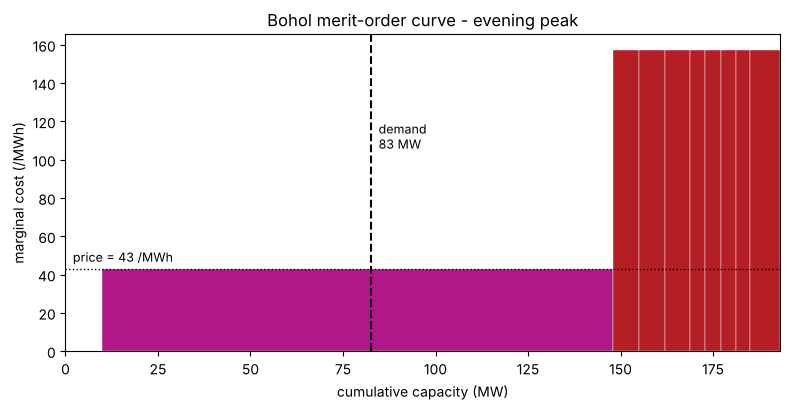

saved figures/04_merit_order.png


In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = 0.0
colors = dict(zip(carriers.name, carriers.color))
for g in mo.itertuples():
    ax.bar(x, g.marginal_cost, width=g.p_nom, align="edge",
           color=colors.get(g.carrier, "grey"), edgecolor="white", linewidth=0.3)
    x += g.p_nom
ax.axvline(demand, color="black", ls="--", lw=1.5)
ax.text(demand + 2, 120, f"demand\n{demand:.0f} MW", va="top", fontsize=9)
ax.axhline(marginal_cost_now, color="black", ls=":", lw=1)
ax.text(2, marginal_cost_now + 4, f"price = {marginal_cost_now:.0f} /MWh", fontsize=9)
ax.set_xlabel("cumulative capacity (MW)")
ax.set_ylabel("marginal cost (/MWh)")
ax.set_title("Bohol merit-order curve - evening peak")
ax.set_xlim(0, mo.cumulative_cap.max())
fig.tight_layout()
fig.savefig(FIG / "04_merit_order.png", dpi=130)
plt.show()
print("saved figures/04_merit_order.png")

### 4.5 Why the price is the marginal unit's cost

`n.buses_t.marginal_price` is the **shadow price** of the demand-balance
constraint: the extra cost of serving one more MW. Since the next MW would come
from the cheapest *un-maxed* plant, the price equals that plant's marginal cost.
Here every cheap unit except the grid is maxed out, the grid is partly loaded,
so the grid sets the price - **42.73 /MWh at all three buses** (no line is
congested, so one uniform price).

In [6]:
print(n.buses_t.marginal_price.iloc[0].round(2).to_string())

name
07CORELLA    42.73
07TAPAL      42.73
07UBAY       42.73


### 4.6 Scarcity: cap the cheap import

What if the submarine cable can only deliver 40 MW (a maintenance limit)? The
solver must now start the **diesel** units to cover the gap. Diesel becomes the
marginal unit, and the price jumps to its cost.

In [7]:
m = bohol(cable_limit=40.0)
m.optimize(**OPT)
disp_m = m.generators_t.p.iloc[0]
print("Dispatch by carrier with the cable capped at 40 MW (MW):")
print(disp_m.groupby(m.generators.carrier).sum().round(2).to_string())
print("\nPrice now:", round(m.buses_t.marginal_price.iloc[0].mean(), 2), "/MWh",
      "(diesel is marginal)")
print("Operating cost:", round(float(m.objective), 1), "per hour",
      f"(was {float(n.objective):.0f}) -> scarcity more than doubles the cost.")

Dispatch by carrier with the cable capped at 40 MW (MW):
carrier
Diesel    32.72
Grid      40.00
Hydro      9.90

Price now: 157.52 /MWh (diesel is marginal)
Operating cost: 6863.4 per hour (was 3107) -> scarcity more than doubles the cost.


## Summary of Chapter 4

- `n.optimize()` chooses the least-cost dispatch; the **merit order** (cheap to
  dear) explains its choice at a glance.
- On a normal peak, Bohol runs **hydro + cable import**, diesel stays off, and
  the uniform price is **42.73 /MWh** - the grid import's cost.
- The **marginal price** always equals the cost of the last unit switched on.
  Cap the cheap cable and diesel sets the price at **157.52 /MWh**: scarcity is
  expensive.
- Next chapter we add a full 24-hour day, renewables and a battery, so the
  dispatch changes hour by hour.



<hr style='border:2px solid #1E81D4'>


# Chapter 5 - A full day: renewables, time series and storage

So far we optimised a single hour. Real systems are driven by **time**: demand
rises and falls, the sun sets, the wind gusts. In this chapter we give PyPSA a
full **24-hour day** with hourly demand and real solar/wind profiles, then add a
**battery** and watch it shift energy from midday to the evening peak.

**Goals of this chapter**
- Use `n.set_snapshots()` and time-varying `p_set` / `p_max_pu`.
- Add variable renewables whose output follows a profile.
- Add a `StorageUnit` battery and read its state of charge.
- Measure what storage buys: less curtailment, less cost, more renewable energy.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
for _n in ("pypsa", "linopy"):
    logging.getLogger(_n).setLevel(logging.ERROR)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypsa

DATA = next(p for p in [Path("data"), Path("../data"), Path("pypsa-bootcamp/data")]
            if (p / "PyPSA_Dataset_Bohol.xlsx").exists())
XLS = DATA / "PyPSA_Dataset_Bohol.xlsx"
FIG = next(p for p in [Path("figures"), Path("../figures")] if p.exists())

buses = pd.read_excel(XLS, "buses")
lines = pd.read_excel(XLS, "lines")
carriers = pd.read_excel(XLS, "carriers")
gens = pd.read_excel(XLS, "generators")
loads_t = pd.read_excel(XLS, "loads_t", index_col=0)
gens_t = pd.read_excel(XLS, "generators_t", index_col=0)
MC = {c.name: c.VOM + c.fuel / c.efficiency for c in carriers.itertuples()}
COLORS = dict(zip(carriers.name, carriers.color))

### 5.1 The time series

`loads_t` is hourly demand per bus; `generators_t` is the hourly **capacity
factor** of solar and wind (a number between 0 and 1: the fraction of rated
power available that hour). Solar is a midday bump, wind blows all day.

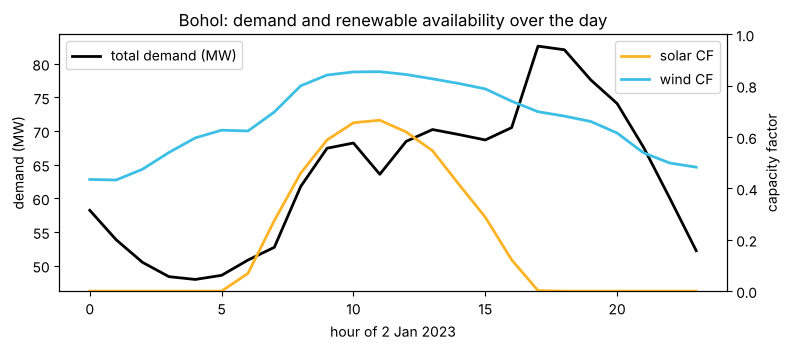

In [2]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(range(24), loads_t.sum(axis=1).values, "k-", lw=2, label="total demand (MW)")
ax2 = ax.twinx()
ax2.plot(range(24), gens_t["SOLAR_BOHOL"].values, color=COLORS["Solar"], lw=2, label="solar CF")
ax2.plot(range(24), gens_t["WIND_BOHOL"].values, color=COLORS["Wind"], lw=2, label="wind CF")
ax.set_xlabel("hour of 2 Jan 2023"); ax.set_ylabel("demand (MW)")
ax2.set_ylabel("capacity factor"); ax2.set_ylim(0, 1)
ax.legend(loc="upper left"); ax2.legend(loc="upper right")
ax.set_title("Bohol: demand and renewable availability over the day")
fig.tight_layout(); fig.savefig(FIG / "05_profiles.png", dpi=130); plt.show()

### 5.2 Build the time-dependent network

Two new modelling ideas:

- A **variable renewable** generator gets a `p_max_pu` time series: its output
  can be anything from 0 up to `p_nom * p_max_pu[t]` each hour (the solver may
  curtail it, but never exceed availability).
- We cap the submarine cable at 45 MW this day (a maintenance limit). That
  creates a real daily squeeze: midday the island has surplus renewable energy,
  the evening peak is tight. Perfect conditions to show what a battery does.

In [3]:
def bohol_day(battery_mw=0.0, solar_mw=60.0, wind_mw=45.0, cable_mw=45.0):
    n = pypsa.Network()
    n.set_snapshots(loads_t.index)              # 24 hourly snapshots
    for b in buses.itertuples():
        n.add("Bus", b.name, v_nom=b.v_nom, x=b.x, y=b.y)
    for c in carriers.itertuples():
        n.add("Carrier", c.name, co2_emissions=c.co2_emissions, color=c.color)
    for l in lines.itertuples():
        n.add("Line", l.name, bus0=l.bus0, bus1=l.bus1, r=l.r, x=l.x, s_nom=l.s_nom)
    # dispatchable fleet (diesel, hydro, capped grid import)
    for g in gens.itertuples():
        p_nom = cable_mw if g.carrier == "Grid" else g.p_nom
        n.add("Generator", g.name, bus=g.bus, carrier=g.carrier,
              p_nom=p_nom, marginal_cost=MC[g.carrier])
    # variable renewables, output capped hour by hour by the profile
    n.add("Generator", "SOLAR", bus="07TAPAL", carrier="Solar", p_nom=solar_mw,
          marginal_cost=MC["Solar"], p_max_pu=gens_t["SOLAR_BOHOL"].values)
    n.add("Generator", "WIND", bus="07UBAY", carrier="Wind", p_nom=wind_mw,
          marginal_cost=MC["Wind"], p_max_pu=gens_t["WIND_BOHOL"].values)
    # optional battery: power rating p_nom, energy = p_nom * max_hours
    if battery_mw:
        n.add("StorageUnit", "BATTERY", bus="07UBAY", carrier="Battery",
              p_nom=battery_mw, max_hours=4, marginal_cost=0.0,
              efficiency_store=1.0, efficiency_dispatch=0.95,
              cyclic_state_of_charge=True)   # end the day as it began
    for bus, col, name in [("07CORELLA", "07CORELLA_LOAD", "Load_Corella"),
                           ("07UBAY", "07UBAY_LOAD", "Load_Ubay")]:
        n.add("Load", name, bus=bus, p_set=loads_t[col].values)
    return n

OPT = dict(solver_name="highs", solver_options={"output_flag": False}, log_to_console=False)

def energy_by_carrier(n):
    return n.generators_t.p.T.groupby(n.generators.carrier).sum().T

### 5.3 Solve the day **without** a battery

Watch what happens at midday: solar and wind together exceed what the island can
use or export, so the solver is forced to **curtail** (spill) free renewable
energy. That spilled energy is the opportunity a battery will capture.

In [4]:
n0 = bohol_day(battery_mw=0.0)
n0.optimize(**OPT)

E0 = energy_by_carrier(n0).sum()
demand = n0.loads_t.p.sum().sum()
avail = (n0.generators[["p_nom"]].T[["SOLAR", "WIND"]].values
         * gens_t[["SOLAR_BOHOL", "WIND_BOHOL"]].values).sum()
used = energy_by_carrier(n0)[["Solar", "Wind"]].sum().sum()
print("Daily demand:", round(demand), "MWh")
print("\nEnergy by carrier (MWh):"); print(E0.round(0).to_string())
print(f"\nRenewable available {avail:.0f} MWh, used {used:.0f} MWh, "
      f"curtailed {avail - used:.0f} MWh")
print(f"Renewable share {100 * used / demand:.1f} % | cost {float(n0.objective):.0f}")

Daily demand: 1516 MWh

Energy by carrier (MWh):
carrier
Diesel      0.0
Grid      382.0
Hydro     238.0
Solar     283.0
Wind      614.0

Renewable available 1001 MWh, used 896 MWh, curtailed 105 MWh
Renewable share 59.1 % | cost 17289


### 5.4 Solve the day **with** a 20 MW / 4 h battery

A `StorageUnit` charges when energy is cheap and plentiful (midday surplus) and
discharges when it is dear (evening peak). `max_hours=4` means its energy store
is 20 MW x 4 h = 80 MWh. `cyclic_state_of_charge=True` forces it to end the day
at the same charge it started, so we are not secretly "borrowing" energy.

In [5]:
n1 = bohol_day(battery_mw=20.0)
n1.optimize(**OPT)

E1 = energy_by_carrier(n1).sum()
used1 = energy_by_carrier(n1)[["Solar", "Wind"]].sum().sum()
soc = n1.storage_units_t.state_of_charge["BATTERY"]
print("Energy by carrier with battery (MWh):"); print(E1.round(0).to_string())
print(f"\nRenewable used {used1:.0f} MWh (was {used:.0f}), "
      f"curtailed {avail - used1:.0f} MWh (was {avail - used:.0f})")
print(f"Renewable share {100 * used1 / demand:.1f} % | cost {float(n1.objective):.0f} "
      f"(was {float(n0.objective):.0f}, a {100*(1-n1.objective/n0.objective):.0f} % saving)")
print(f"Battery energy swing: {soc.min():.0f} to {soc.max():.0f} MWh")

Energy by carrier with battery (MWh):
carrier
Diesel      0.0
Grid      306.0
Hydro     238.0
Solar     283.0
Wind      694.0

Renewable used 976 MWh (was 896), curtailed 25 MWh (was 105)
Renewable share 64.4 % | cost 14169 (was 17289, a 18 % saving)
Battery energy swing: -0 to 80 MWh


### 5.5 Picture the day: generation stack and battery

The stack shows who supplies each hour; the black line is demand. The battery
panel below shows it **charging** (negative) at midday and **discharging**
(positive) in the evening - textbook load-shifting.

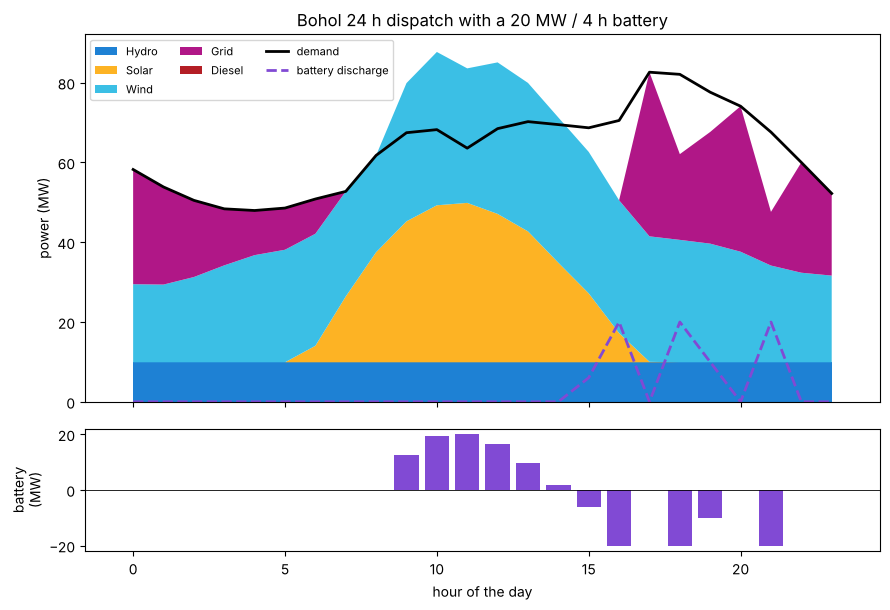

saved figures/05_dispatch_storage.png


In [6]:
hours = range(24)
order = ["Hydro", "Solar", "Wind", "Grid", "Diesel"]
stack = energy_by_carrier(n1).reindex(columns=order, fill_value=0.0)
batt_p = n1.storage_units_t.p["BATTERY"]

fig, (axA, axB) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
axA.stackplot(hours, [stack[c].values for c in order],
              labels=order, colors=[COLORS[c] for c in order])
axA.plot(hours, n1.loads_t.p.sum(axis=1).values, "k-", lw=2, label="demand")
axA.plot(hours, batt_p.clip(lower=0).values, color=COLORS["Battery"], lw=2,
         ls="--", label="battery discharge")
axA.set_ylabel("power (MW)"); axA.legend(ncol=3, fontsize=8, loc="upper left")
axA.set_title("Bohol 24 h dispatch with a 20 MW / 4 h battery")

axB.bar(hours, (-batt_p).values, color=COLORS["Battery"],
        label="charge (+) / discharge (-)")
axB.axhline(0, color="k", lw=0.6)
axB.set_ylabel("battery\n(MW)"); axB.set_xlabel("hour of the day")
fig.tight_layout(); fig.savefig(FIG / "05_dispatch_storage.png", dpi=130); plt.show()
print("saved figures/05_dispatch_storage.png")

## Summary of Chapter 5

- `n.set_snapshots()` turns a one-shot model into a time series; renewables use
  a `p_max_pu` profile so their ceiling moves hour by hour.
- Without storage, the island must **curtail ~105 MWh** of free renewable energy
  at midday because it cannot use or export it.
- A 20 MW / 4 h `StorageUnit` charges on the midday surplus and discharges at the
  evening peak: **curtailment falls to ~25 MWh, cost drops ~18 %, and the
  renewable share rises** - with no extra fuel.
- Next chapter we add two policy-style constraints: a **CO2 cap** and a
  **congested line**.



<hr style='border:2px solid #1E81D4'>


# Chapter 6 - Congestion, nodal prices and N-1 security

Until now the grid has been roomy: every bus paid the same price. But lines have
limits. When a cheap plant cannot reach a load because the line in between is
full, the grid is **congested**: the load must be served by a dearer local plant,
and the two buses no longer share one price. Operators also plan for the loss of
any single line - the **N-1 criterion** - so a fault never blacks out the island.

**Goals of this chapter**
- See a line hit 100 % loading and create a **nodal (locational) price** split.
- Understand **loop flow**: parallel lines share current by impedance, not by rating.
- Run an **N-1 contingency** screen and read a security table.
- Connect all of this back to the merit order of Chapter 4.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
for _n in ("pypsa", "linopy"):
    logging.getLogger(_n).setLevel(logging.ERROR)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypsa

DATA = next(p for p in [Path("data"), Path("../data"), Path("pypsa-bootcamp/data")]
            if (p / "PyPSA_Dataset_Bohol.xlsx").exists())
XLS = DATA / "PyPSA_Dataset_Bohol.xlsx"
FIG = next(p for p in [Path("figures"), Path("../figures")] if p.exists())

buses = pd.read_excel(XLS, "buses")
lines = pd.read_excel(XLS, "lines")
carriers = pd.read_excel(XLS, "carriers")
gens = pd.read_excel(XLS, "generators")
loads_t = pd.read_excel(XLS, "loads_t", index_col=0)
MC = {c.name: c.VOM + c.fuel / c.efficiency for c in carriers.itertuples()}
PEAK = loads_t.sum(axis=1).idxmax()
OPT = dict(solver_name="highs", solver_options={"output_flag": False}, log_to_console=False)

### 6.1 A builder with adjustable corridor rating and line outages

The two parallel Ubay-Corella lines are the island's main corridor. We give the
builder a knob for their rating and the ability to drop any line, so we can
study congestion and contingencies with one function. We model the evening peak.

In [2]:
def peak_network(corridor_mva=None, drop_line=None):
    # corridor_mva=None keeps the real dataset ratings (138 and 69 MVA);
    # a number overrides the two Ubay-Corella lines to study congestion.
    n = pypsa.Network()
    for b in buses.itertuples():
        n.add("Bus", b.name, v_nom=b.v_nom, x=b.x, y=b.y)
    for c in carriers.itertuples():
        n.add("Carrier", c.name, co2_emissions=c.co2_emissions, color=c.color)
    for l in lines.itertuples():
        if drop_line and l.name == drop_line:
            continue                       # this line is out of service
        s_nom = corridor_mva if (corridor_mva and "CORELLA" in l.name) else l.s_nom
        n.add("Line", l.name, bus0=l.bus0, bus1=l.bus1, r=l.r, x=l.x, s_nom=s_nom)
    for g in gens.itertuples():
        n.add("Generator", g.name, bus=g.bus, carrier=g.carrier,
              p_nom=g.p_nom, marginal_cost=MC[g.carrier])
    for bus, col, name in [("07CORELLA", "07CORELLA_LOAD", "Load_Corella"),
                           ("07UBAY", "07UBAY_LOAD", "Load_Ubay")]:
        n.add("Load", name, bus=bus, p_set=float(loads_t.loc[PEAK, col]))
    return n

def loading_pct(n):
    # linear OPF reports active-power flow p0; loading = |p0| / rating
    return (100 * np.abs(n.lines_t.p0).iloc[0] / n.lines.s_nom).round(1)

### 6.2 The uncongested base case

At the real line ratings (138 and 69 MVA), the cheap grid import reaches Corella
freely. Every bus pays the import price (42.73), and the lines sit around 20 %.

In [3]:
base = peak_network()
base.optimize(**OPT)
print("Line loading (%):")
print(loading_pct(base).to_string())
print("\nNodal prices (/MWh):")
print(base.buses_t.marginal_price.iloc[0].round(2).to_string())
print("\nDiesel running:", round(base.generators_t.p.iloc[0]
      .groupby(base.generators.carrier).sum().get("Diesel", 0), 1), "MW")

Line loading (%):
name
69_07UBAY_07TAPAL        0.0
138_07UBAY_07CORELLA    23.9
69_07UBAY_07CORELLA     17.0

Nodal prices (/MWh):
name
07CORELLA    42.73
07TAPAL      42.73
07UBAY       42.73

Diesel running: 0.0 MW


### 6.3 Congest the corridor

Now cap each corridor line at **30 MVA** (a hot-weather derating). Corella's
~53 MW peak can no longer be fully imported, so the solver must start **local
diesel**. Two things happen at once:

- the price at Corella jumps to the diesel cost (157.52), while Ubay stays at
  42.73 - a **nodal price split** caused purely by the congested line;
- the stronger 138 kV line hits **100 %** while its 69 kV neighbour is only
  ~36 % loaded. The current does not split by rating but by **impedance** - the
  lower-reactance line attracts more flow. This is **loop flow**.

In [4]:
cong = peak_network(corridor_mva=30.0)
cong.optimize(**OPT)
load = loading_pct(cong)
price = cong.buses_t.marginal_price.iloc[0]
print("Line loading (%):"); print(load.to_string())
print("\nNodal prices (/MWh):"); print(price.round(2).to_string())
disp = cong.generators_t.p.iloc[0].groupby(cong.generators.carrier).sum()
print("\nDispatch (MW): diesel %.1f, grid %.1f, hydro %.1f"
      % (disp.get("Diesel", 0), disp.get("Grid", 0), disp.get("Hydro", 0)))
print("Congestion rent / extra cost vs base: %.0f per hour"
      % (cong.objective - base.objective))

Line loading (%):
name
69_07UBAY_07TAPAL         0.0
138_07UBAY_07CORELLA    100.0
69_07UBAY_07CORELLA      35.7

Nodal prices (/MWh):
name
07CORELLA    157.52
07TAPAL       42.73
07UBAY        42.73

Dispatch (MW): diesel 4.0, grid 68.7, hydro 9.9
Congestion rent / extra cost vs base: 458 per hour


### 6.4 Picture the price split

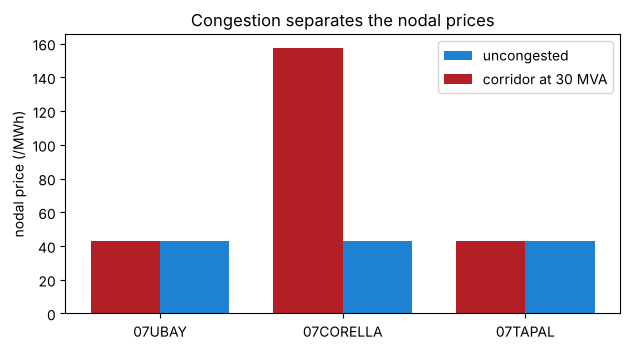

saved figures/06_nodal_prices.png


In [5]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
b = ["07UBAY", "07CORELLA", "07TAPAL"]
ax.bar(b, [base.buses_t.marginal_price.iloc[0][x] for x in b],
       width=0.38, align="edge", label="uncongested", color="#1E81D4")
ax.bar(b, [price[x] for x in b], width=-0.38, align="edge",
       label="corridor at 30 MVA", color="#B41E25")
ax.set_ylabel("nodal price (/MWh)")
ax.set_title("Congestion separates the nodal prices")
ax.legend()
fig.tight_layout(); fig.savefig(FIG / "06_nodal_prices.png", dpi=130); plt.show()
print("saved figures/06_nodal_prices.png")

### 6.5 N-1 security screen

A secure system survives the loss of **any one line**. We drop each line in turn,
re-optimise, and record the worst line loading, whether diesel had to start, and
the cost. If any case cannot be solved, that outage would **shed load** - a
security violation. We run the screen twice: with a strong corridor and with the
congested one.

In [6]:
def n1_screen(corridor_mva=None):
    rows = []
    all_lines = peak_network(corridor_mva).lines.index
    for out in [None] + list(all_lines):
        n = peak_network(corridor_mva, drop_line=out)
        status, _ = n.optimize(**OPT)
        if status != "ok" or n.generators_t.p.empty:
            rows.append({"outage": out or "intact", "feasible": "NO (load shed)",
                         "worst line %": np.nan, "diesel MW": np.nan, "cost": np.nan})
            continue
        load = loading_pct(n)
        disp = n.generators_t.p.iloc[0].groupby(n.generators.carrier).sum()
        rows.append({"outage": out or "intact", "feasible": "yes",
                     "worst line %": load.max(),
                     "diesel MW": round(disp.get("Diesel", 0), 1),
                     "cost": round(float(n.objective))})
    return pd.DataFrame(rows).set_index("outage")

print("Real ratings (138 / 69 MVA) - N-1 secure:")
print(n1_screen(None).to_string())
print("\nDerated corridor (30 MVA each) - N-1 stressed:")
print(n1_screen(30.0).to_string())

Real ratings (138 / 69 MVA) - N-1 secure:


                     feasible  worst line %  diesel MW  cost
outage                                                      
intact                    yes          23.9        0.0  3107
69_07UBAY_07TAPAL         yes          23.9        0.0  3107
138_07UBAY_07CORELLA      yes          64.8        0.0  3107
69_07UBAY_07CORELLA       yes          32.4        0.0  3107

Derated corridor (30 MVA each) - N-1 stressed:


                     feasible  worst line %  diesel MW  cost
outage                                                      
intact                    yes         100.0        4.0  3565
69_07UBAY_07TAPAL         yes         100.0        4.0  3565
138_07UBAY_07CORELLA      yes         100.0       14.7  4795
69_07UBAY_07CORELLA       yes         100.0       14.7  4795


**Read the screen.** At the real ratings every outage is feasible and the worst
remaining line stays around 65 % - the island is **N-1 secure**. With the derated
corridor, losing the 138 kV line pins the surviving 69 kV line at **100 %** and
forces ~15 MW of diesel: the system still stands, but only by burning expensive
fuel. That gap between "feasible" and "cheap" is exactly what a planner invests
to close - the subject of Chapter 7.

## Summary of Chapter 6

- A **congested** line stops cheap power reaching a load; the load bus then pays
  its local plant's cost, so **nodal prices separate** (Corella 157.52 vs Ubay
  42.73).
- Parallel lines share current by **impedance, not rating** (loop flow), so the
  138 kV line saturates while the 69 kV line is half empty.
- An **N-1 screen** re-optimises for the loss of each line. Bohol is secure at
  full ratings; derated, a single outage leaves it leaning hard on diesel.
- Next chapter we let PyPSA **build** new capacity - and finally make a CO2 cap
  bite - by optimising investment, not just operation.



<hr style='border:2px solid #1E81D4'>


# Chapter 7 - Capacity expansion: what to build, and a CO2 cap that bites

Every chapter so far took the power plants as given and asked *how to operate*
them. Planning asks the harder question: **what should we build?** PyPSA answers
it by making a component's capacity a *decision variable* (`p_nom_extendable`)
and adding its **annualised build cost** to the objective. The solver then
minimises **capital + operating cost together**.

This is also where a **CO2 cap** finally changes the answer. In a pure dispatch
model the cheapest plants here are already the cleanest, so a carbon limit does
nothing. Once the model can *build*, the cap forces it to invest in more solar
and storage - at a cost we can measure exactly.

**Goals of this chapter**
- Make solar, wind and a battery **extendable** and read the optimal build.
- Split the total cost into **capital** and **operating** parts.
- Sweep a CO2 cap and draw the **cost-vs-carbon trade-off curve**.
- Meet the **feasibility wall**: why a short battery cannot decarbonise the night.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
for _n in ("pypsa", "linopy"):
    logging.getLogger(_n).setLevel(logging.ERROR)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypsa

DATA = next(p for p in [Path("data"), Path("../data"), Path("pypsa-bootcamp/data")]
            if (p / "PyPSA_Dataset_Bohol.xlsx").exists())
XLS = DATA / "PyPSA_Dataset_Bohol.xlsx"
FIG = next(p for p in [Path("figures"), Path("../figures")] if p.exists())

buses = pd.read_excel(XLS, "buses")
lines = pd.read_excel(XLS, "lines")
carriers = pd.read_excel(XLS, "carriers")
gens = pd.read_excel(XLS, "generators")
loads_t = pd.read_excel(XLS, "loads_t", index_col=0)
gens_t = pd.read_excel(XLS, "generators_t", index_col=0)
MC = {c.name: c.VOM + c.fuel / c.efficiency for c in carriers.itertuples()}
CO2 = dict(zip(carriers.name, carriers.co2_emissions))
COLORS = dict(zip(carriers.name, carriers.color))

### 7.1 The annualised capital cost

A solar farm is paid for once but runs for decades. To compare it with one day
of fuel, we spread its build cost over its lifetime and express it **per day**:

> capital_cost = (1 + FOM) * investment / (lifetime * 365.25)

`investment` is the overnight cost per MW, `FOM` the yearly fixed O&M as a
fraction, `lifetime` the years of service. Our optimisation horizon is one
representative day, so a per-day capital cost trades off correctly against the
day's fuel bill.

In [2]:
CAP = {c.name: (1 + c.FOM) * c.investment / (c.lifetime * 365.25)
       for c in carriers.itertuples()}
print("Annualised capital cost (per MW per day):")
for k in ["Solar", "Wind", "Battery"]:
    print(f"  {k:8s} {CAP[k]:7.1f}   (marginal cost {MC[k]:.2f}/MWh)")

Annualised capital cost (per MW per day):
  Solar      163.3   (marginal cost 0.01/MWh)
  Wind       270.3   (marginal cost 1.59/MWh)
  Battery     40.3   (marginal cost 0.00/MWh)


### 7.2 Build the expansion model

The **existing fleet** (diesel, hydro, the grid cable) keeps its fixed capacity.
We add three **candidate** investments with `p_nom_extendable=True` and an upper
limit `p_nom_max` that represents how much land / how many good sites the island
has. The battery is a `StorageUnit` with `max_hours=8` (an 8-hour energy store).

In [3]:
def expansion(co2_cap=None):
    n = pypsa.Network()
    n.set_snapshots(loads_t.index)
    for b in buses.itertuples():
        n.add("Bus", b.name, v_nom=b.v_nom, x=b.x, y=b.y)
    for c in carriers.itertuples():
        n.add("Carrier", c.name, co2_emissions=c.co2_emissions, color=c.color)
    for l in lines.itertuples():
        n.add("Line", l.name, bus0=l.bus0, bus1=l.bus1, r=l.r, x=l.x, s_nom=l.s_nom)
    # existing fleet: capacity fixed
    for g in gens.itertuples():
        n.add("Generator", g.name, bus=g.bus, carrier=g.carrier,
              p_nom=g.p_nom, marginal_cost=MC[g.carrier])
    # candidate new build: capacity is a decision variable, capped by siting
    n.add("Generator", "SOLAR_new", bus="07TAPAL", carrier="Solar",
          p_nom_extendable=True, p_nom_max=150, capital_cost=CAP["Solar"],
          marginal_cost=MC["Solar"], p_max_pu=gens_t["SOLAR_BOHOL"].values)
    n.add("Generator", "WIND_new", bus="07UBAY", carrier="Wind",
          p_nom_extendable=True, p_nom_max=30, capital_cost=CAP["Wind"],
          marginal_cost=MC["Wind"], p_max_pu=gens_t["WIND_BOHOL"].values)
    n.add("StorageUnit", "BATT_new", bus="07UBAY", carrier="Battery",
          p_nom_extendable=True, p_nom_max=200, capital_cost=CAP["Battery"],
          max_hours=8, marginal_cost=0.0, efficiency_dispatch=0.95,
          efficiency_store=1.0, cyclic_state_of_charge=True)
    for bus, col, name in [("07CORELLA", "07CORELLA_LOAD", "Load_Corella"),
                           ("07UBAY", "07UBAY_LOAD", "Load_Ubay")]:
        n.add("Load", name, bus=bus, p_set=loads_t[col].values)
    if co2_cap is not None:
        n.add("GlobalConstraint", "co2_limit", carrier_attribute="co2_emissions",
              sense="<=", constant=co2_cap)
    return n

OPT = dict(solver_name="highs", solver_options={"output_flag": False}, log_to_console=False)

def emissions(n):
    return float((n.generators_t.p.sum() * n.generators.carrier.map(CO2)).sum())

### 7.3 The least-cost build (no carbon policy)

First we let cost alone decide. Note the result before reading on: on this windy,
sunny day the solver **chooses** a largely renewable island - clean energy is not
a sacrifice here, it is the cheapest plan.

In [4]:
base = expansion()
base.optimize(**OPT)

build = pd.Series({
    "solar (MW)": base.generators.p_nom_opt["SOLAR_new"],
    "wind (MW)": base.generators.p_nom_opt["WIND_new"],
    "battery (MW)": base.storage_units.p_nom_opt["BATT_new"],
})
e0 = emissions(base)
print("Optimal new build:"); print(build.round(1).to_string())
print(f"\nTotal cost: {base.objective:,.0f} per day | CO2: {e0:.1f} tonnes")

Optimal new build:
solar (MW)      105.2
wind (MW)        30.0
battery (MW)     36.3

Total cost: 41,138 per day | CO2: 35.1 tonnes


### 7.4 Capital vs operating cost

The objective is the sum of **capital** (building the new solar/wind/battery) and
**operating** cost (fuel for whatever still runs). Splitting them shows where the
money goes.

In [5]:
cap_cost = (base.generators.p_nom_opt[["SOLAR_new", "WIND_new"]]
            * pd.Series({"SOLAR_new": CAP["Solar"], "WIND_new": CAP["Wind"]})).sum()
cap_cost += base.storage_units.p_nom_opt["BATT_new"] * CAP["Battery"]
op_cost = (base.generators_t.p.sum() * base.generators.marginal_cost).sum()
print(f"Capital cost (new build)   : {cap_cost:8,.0f} per day")
print(f"Operating cost (fuel, etc.): {op_cost:8,.0f} per day")
print(f"Total                      : {cap_cost + op_cost:8,.0f} per day")
E = base.generators_t.p.T.groupby(base.generators.carrier).sum().T.sum()
print("\nEnergy by source (MWh):"); print(E.round(0).to_string())

Capital cost (new build)   :   26,750 per day
Operating cost (fuel, etc.):   14,388 per day
Total                      :   41,138 per day

Energy by source (MWh):
carrier
Diesel      0.0
Grid      319.0
Hydro     238.0
Solar     494.0
Wind      474.0


### 7.5 A CO2 cap that bites

Now tighten a carbon cap step by step, from today's emissions down. Each step the
solver must **invest more** (more solar, more battery) to burn less. We record the
cost and the build at every level to draw the trade-off curve.

In [6]:
rows = []
for frac in [1.00, 0.90, 0.85, 0.80, 0.75, 0.72, 0.70, 0.68, 0.60]:
    cap = None if frac == 1.00 else e0 * frac
    m = expansion(co2_cap=cap)
    status, _ = m.optimize(**OPT)
    if status != "ok":
        rows.append({"CO2 cap (t)": round(e0 * frac, 1), "feasible": "NO",
                     "cost": np.nan, "extra %": np.nan,
                     "solar": np.nan, "battery": np.nan})
        continue
    rows.append({"CO2 cap (t)": round(e0 * frac, 1), "feasible": "yes",
                 "cost": round(m.objective), "extra %": round(100 * (m.objective / base.objective - 1), 1),
                 "solar": round(m.generators.p_nom_opt["SOLAR_new"]),
                 "battery": round(m.storage_units.p_nom_opt["BATT_new"])})
curve = pd.DataFrame(rows)
print(curve.to_string(index=False))

 CO2 cap (t) feasible    cost  extra %  solar  battery
        35.1      yes 41138.0      0.0  105.0     36.0
        31.6      yes 41439.0      0.7  114.0     41.0
        29.8      yes 41872.0      1.8  121.0     41.0
        28.1      yes 42579.0      3.5  129.0     41.0
        26.3      yes 43567.0      5.9  140.0     41.0
        25.3      yes 44160.0      7.3  146.0     41.0
        24.6      yes 44561.0      8.3  150.0     41.0
        23.9       NO     NaN      NaN    NaN      NaN
        21.1       NO     NaN      NaN    NaN      NaN


### 7.6 The trade-off curve and the feasibility wall

Plotting cost against the carbon cap shows the classic shape: cheap at first, then
steepening as each extra tonne avoided needs more over-built solar and storage -
until a **wall**. Below ~70 % of today's emissions the problem is **infeasible**:
an 8-hour battery and a single solar site simply cannot carry the long tropical
night. The last stretch of decarbonisation needs something this toolbox of
options does not have - **long-duration storage or firm clean capacity**.

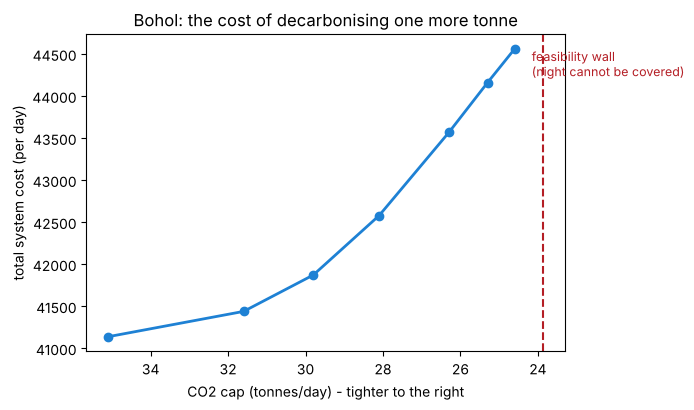

saved figures/07_tradeoff.png


In [7]:
ok = curve[curve.feasible == "yes"]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(ok["CO2 cap (t)"], ok["cost"], "o-", color="#1E81D4", lw=2)
ax.axvline(e0 * 0.68, color="#B41E25", ls="--", lw=1.5)
ax.text(e0 * 0.68 + 0.3, ok["cost"].max(), "feasibility wall\n(night cannot be covered)",
        color="#B41E25", fontsize=9, va="top")
ax.invert_xaxis()                      # tighter cap to the right
ax.set_xlabel("CO2 cap (tonnes/day) - tighter to the right")
ax.set_ylabel("total system cost (per day)")
ax.set_title("Bohol: the cost of decarbonising one more tonne")
fig.tight_layout(); fig.savefig(FIG / "07_tradeoff.png", dpi=130); plt.show()
print("saved figures/07_tradeoff.png")

## Summary of Chapter 7

- `p_nom_extendable=True` turns capacity into a decision; `capital_cost`
  (annualised per day) lets the solver weigh **building vs buying fuel**.
- Left to cost alone, the least-cost Bohol island is **already mostly renewable**
  (solar + wind + an 8 h battery) and emits little - clean is cheap here.
- A **CO2 cap** does bite once we can invest: tightening it from 100 % to 70 % of
  today's emissions **raises cost by ~8 %** as the model over-builds solar and
  storage.
- Below ~70 % the problem is **infeasible with a short battery**: the real
  bottleneck is covering the night, which needs long-duration storage or firm
  capacity. That honest limit is the whole point of planning with a model.
- Next chapter we put every tool together in one capstone case study.



<hr style='border:2px solid #1E81D4'>


# Chapter 8 - Capstone: the Bohol island, four scenarios

This final chapter puts every tool from the bootcamp into one decision-grade
study. We model the **whole Bohol island** over a full day and compare four
futures a planner would actually weigh:

| Scenario | Question it answers |
| --- | --- |
| **BAU** | What does today's diesel-and-import system cost and emit? |
| **+ Renewables** | What do 60 MW solar + 45 MW wind change? |
| **+ Battery** | Does a 20 MW / 4 h battery add value on top? |
| **Islanded** | If the submarine cable fails, does the island stay up? |

Every scenario is solved with `n.optimize()`; a high-cost "load-shedding"
generator stands in for unserved energy, so a shortfall shows up as **shed MWh**
instead of a solver failure - exactly how a real study flags a security risk.

**Goals of this chapter**
- Assemble the full dataset into one reusable builder.
- Compare scenarios on cost, CO2, renewable share and security.
- Read the recommended dispatch and the island network on a map.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
for _n in ("pypsa", "linopy"):
    logging.getLogger(_n).setLevel(logging.ERROR)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypsa

DATA = next(p for p in [Path("data"), Path("../data"), Path("pypsa-bootcamp/data")]
            if (p / "PyPSA_Dataset_Bohol.xlsx").exists())
XLS = DATA / "PyPSA_Dataset_Bohol.xlsx"
FIG = next(p for p in [Path("figures"), Path("../figures")] if p.exists())

buses = pd.read_excel(XLS, "buses")
lines = pd.read_excel(XLS, "lines")
carriers = pd.read_excel(XLS, "carriers")
gens = pd.read_excel(XLS, "generators")
loads_t = pd.read_excel(XLS, "loads_t", index_col=0)
gens_t = pd.read_excel(XLS, "generators_t", index_col=0)
MC = {c.name: c.VOM + c.fuel / c.efficiency for c in carriers.itertuples()}
CO2 = dict(zip(carriers.name, carriers.co2_emissions))
COLORS = dict(zip(carriers.name, carriers.color))
OPT = dict(solver_name="highs", solver_options={"output_flag": False}, log_to_console=False)

### 8.1 One builder for every scenario

Flags turn each option on or off. `VOLL` (value of lost load) is the make-believe
price of shedding - far above any real generator, so the solver sheds only when it
physically must, and the amount shed measures the security gap.

In [2]:
VOLL = 5000.0   # currency per MWh of unserved energy

def bohol(renewables=False, battery=False, islanded=False):
    n = pypsa.Network()
    n.set_snapshots(loads_t.index)
    for b in buses.itertuples():
        n.add("Bus", b.name, v_nom=b.v_nom, x=b.x, y=b.y)
    for c in carriers.itertuples():
        n.add("Carrier", c.name, co2_emissions=c.co2_emissions, color=c.color)
    for l in lines.itertuples():
        n.add("Line", l.name, bus0=l.bus0, bus1=l.bus1, r=l.r, x=l.x, s_nom=l.s_nom)
    # existing fleet; the grid cable is lost when islanded
    for g in gens.itertuples():
        p_nom = 0.0 if (g.carrier == "Grid" and islanded) else g.p_nom
        n.add("Generator", g.name, bus=g.bus, carrier=g.carrier,
              p_nom=p_nom, marginal_cost=MC[g.carrier])
    if renewables:
        n.add("Generator", "SOLAR", bus="07TAPAL", carrier="Solar", p_nom=60,
              marginal_cost=MC["Solar"], p_max_pu=gens_t["SOLAR_BOHOL"].values)
        n.add("Generator", "WIND", bus="07UBAY", carrier="Wind", p_nom=45,
              marginal_cost=MC["Wind"], p_max_pu=gens_t["WIND_BOHOL"].values)
    if battery:
        n.add("StorageUnit", "BATTERY", bus="07UBAY", carrier="Battery", p_nom=20,
              max_hours=4, marginal_cost=0.0, efficiency_dispatch=0.95,
              efficiency_store=1.0, cyclic_state_of_charge=True)
    # load-shedding proxy at each load bus (not a real plant)
    for b in ["07CORELLA", "07UBAY"]:
        n.add("Generator", "shed_" + b, bus=b, carrier="Grid", p_nom=300,
              marginal_cost=VOLL)
    for bus, col, name in [("07CORELLA", "07CORELLA_LOAD", "Load_Corella"),
                           ("07UBAY", "07UBAY_LOAD", "Load_Ubay")]:
        n.add("Load", name, bus=bus, p_set=loads_t[col].values)
    return n

### 8.2 A KPI reader

From a solved network we pull the numbers a decision rests on: real operating
cost (excluding the fictitious shedding), CO2, renewable share, fuel use and any
unserved energy.

In [3]:
def kpis(n):
    p = n.generators_t.p
    is_shed = p.columns.str.startswith("shed_")
    real = p.loc[:, ~is_shed]
    shed_mwh = p.loc[:, is_shed].to_numpy().sum()
    carrier = n.generators.carrier
    energy = real.T.groupby(carrier[real.columns]).sum().T.sum()
    demand = n.loads_t.p.to_numpy().sum()
    op_cost = (real.sum() * n.generators.marginal_cost[real.columns]).sum()
    co2 = float((real.sum() * carrier[real.columns].map(CO2)).sum())
    renew = energy.get("Solar", 0.0) + energy.get("Wind", 0.0)
    return {
        "op cost": round(op_cost),
        "CO2 (t)": round(co2, 1),
        "renew %": round(100 * renew / demand, 1),
        "diesel MWh": round(energy.get("Diesel", 0.0)),
        "grid MWh": round(energy.get("Grid", 0.0)),
        "shed MWh": round(shed_mwh, 1),
    }

### 8.3 Run the four scenarios

In [4]:
scenarios = {
    "BAU (diesel + import)": bohol(),
    "+ Renewables": bohol(renewables=True),
    "+ Renewables + Battery": bohol(renewables=True, battery=True),
    "Islanded (cable lost)": bohol(renewables=True, battery=True, islanded=True),
}
table = {}
for name, n in scenarios.items():
    n.optimize(**OPT)
    table[name] = kpis(n)

summary = pd.DataFrame(table).T
print(summary.to_string())

                        op cost  CO2 (t)  renew %  diesel MWh  grid MWh  shed MWh
BAU (diesel + import)   54612.0    140.6      0.0         0.0    1278.0       0.0
+ Renewables            17289.0     42.0     59.1         0.0     382.0       0.0
+ Renewables + Battery  14169.0     33.6     64.4         0.0     306.0       0.0
Islanded (cable lost)   49268.0     78.6     64.4       306.0       0.0       0.0


**Read the table.**

- **Renewables transform the economics**: operating cost falls from ~54,600 to
  ~17,300 per day (about **-68 %**) and CO2 from ~141 to ~42 tonnes, as 60 MW of
  solar and 45 MW of wind displace imported and diesel energy.
- **The battery adds a further ~18 %** cost cut and lifts the renewable share to
  ~64 %, by shifting midday surplus into the evening (Chapter 5's lesson, now in a
  full system).
- **The island survives the cable loss with zero shed energy**: local diesel,
  hydro, renewables and the battery cover every hour. It is dearer (diesel is
  expensive) but the lights stay on - a concrete N-security result.

### 8.4 The recommended dispatch, hour by hour

The "+ Renewables + Battery" plan is the everyday recommendation. Here is how it
serves the day.

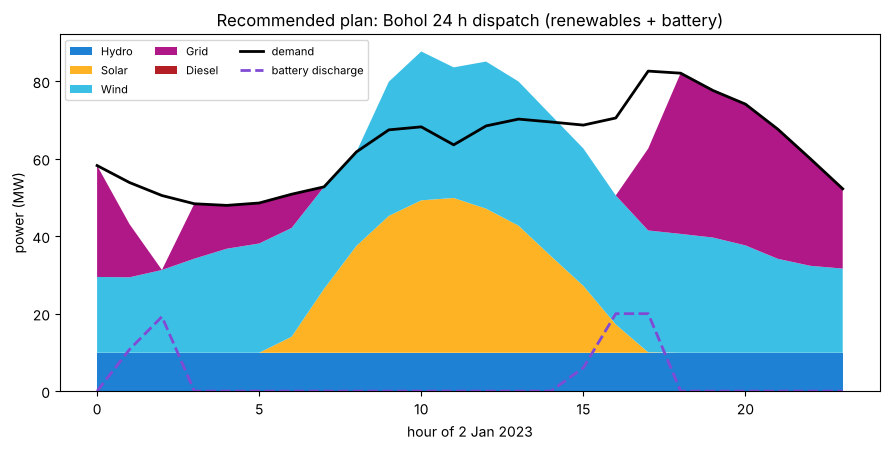

saved figures/08_recommended_dispatch.png


In [5]:
rec = scenarios["+ Renewables + Battery"]
order = ["Hydro", "Solar", "Wind", "Grid", "Diesel"]
p = rec.generators_t.p
p = p.loc[:, ~p.columns.str.startswith("shed_")]
stack = p.T.groupby(rec.generators.carrier[p.columns]).sum().T.reindex(columns=order, fill_value=0.0)
batt = rec.storage_units_t.p["BATTERY"]
hours = range(24)

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.stackplot(hours, [stack[c].values for c in order], labels=order,
             colors=[COLORS[c] for c in order])
ax.plot(hours, rec.loads_t.p.sum(axis=1).values, "k-", lw=2, label="demand")
ax.plot(hours, batt.clip(lower=0).values, "--", color=COLORS["Battery"], lw=2,
        label="battery discharge")
ax.set_xlabel("hour of 2 Jan 2023"); ax.set_ylabel("power (MW)")
ax.set_title("Recommended plan: Bohol 24 h dispatch (renewables + battery)")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "08_recommended_dispatch.png", dpi=130); plt.show()
print("saved figures/08_recommended_dispatch.png")

### 8.5 The island on a map

Using the real coordinates in the dataset, we draw the three buses and the lines
between them - the physical system behind all the numbers.

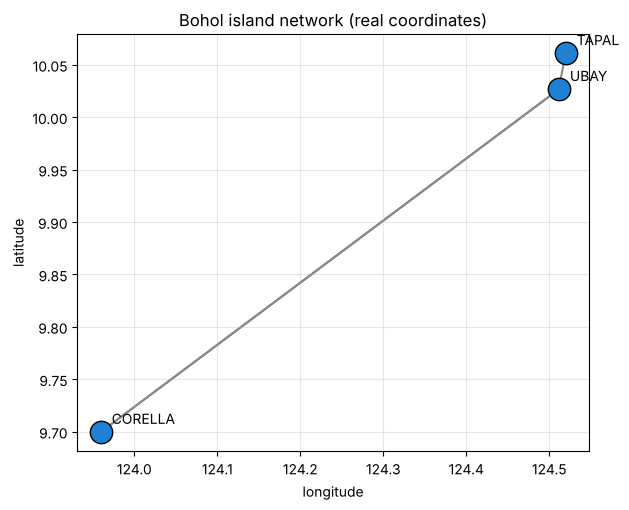

saved figures/08_network_map.png


In [6]:
fig, ax = plt.subplots(figsize=(6.4, 5.2))
for l in lines.itertuples():
    b0, b1 = buses.set_index("name").loc[l.bus0], buses.set_index("name").loc[l.bus1]
    ax.plot([b0.x, b1.x], [b0.y, b1.y], "-", color="#888", lw=1.5, zorder=1)
sizes = loads_t.max()  # peak load as a marker-size hint
for b in buses.itertuples():
    ax.scatter(b.x, b.y, s=260, color="#1E81D4", edgecolor="k", zorder=2)
    ax.annotate(b.name.replace("07", ""), (b.x, b.y),
                textcoords="offset points", xytext=(8, 6), fontsize=10)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("Bohol island network (real coordinates)")
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "08_network_map.png", dpi=130); plt.show()
print("saved figures/08_network_map.png")

## Summary of the capstone

- One dataset, one builder, four scenarios: the bootcamp's full toolkit on a real
  island.
- **Renewables cut operating cost ~68 % and CO2 ~70 %**; a **battery adds another
  ~18 %** and lifts the renewable share to ~64 %.
- **The island rides through the loss of its submarine cable with no load shed** -
  costlier, but secure.
- The recommended everyday plan is clear from the numbers and the dispatch chart,
  and you built every piece of the reasoning yourself.

### Where to go next
- Swap in a full year of weather (8760 snapshots) instead of one day.
- Make capacities extendable (Chapter 7) to co-optimise build **and** operation.
- Add an N-1 security constraint (Chapter 6) to the capacity plan.
- Plug in real Renewables.ninja profiles once you have an API token.

You now have the complete workflow: build, power flow, dispatch, time series,
storage, security and investment - the core of professional power-system analysis
with PyPSA.